In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [ ]:
df = yf.download('AAPL', period='1y')
df

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,MSTR,MSTR,MSTR,MSTR,MSTR
Date,,,,,
2026-04-10,128.639999,132.279999,127.400002,130.050003,13097500
2026-04-13,132.360001,132.490005,125.040001,126.650002,12804700
2026-04-14,137.410004,143.699997,136.320007,137.929993,20643200
2026-04-15,143.539993,143.750000,135.490005,139.750000,13941700
2026-04-16,148.940002,149.160004,139.330002,143.210007,17638000
...,...,...,...,...,...
2026-10-05,164.429993,166.199997,160.119995,164.679993,18216500
2026-10-06,164.550003,168.729996,163.179993,165.820007,17497200


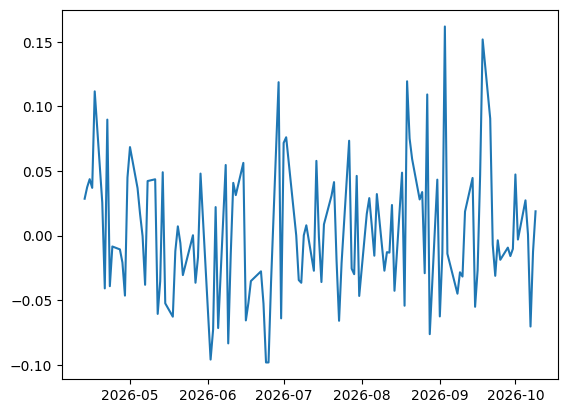

In [25]:
df["logreturn"] = np.log(df["Close"] / df["Close"].shift(1))
plt.plot(df.index, df["logreturn"])

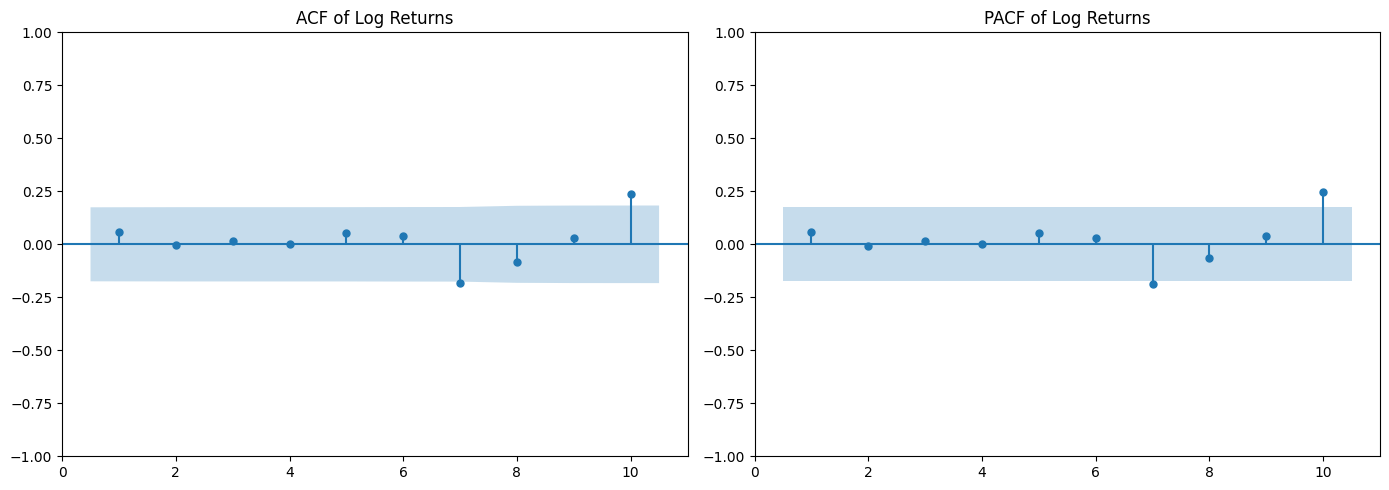

In [30]:
log_returns = df["logreturn"].dropna()

# Create side-by-side subplots for ACF and PACF
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot ACF
plot_acf(log_returns, lags=10, ax=ax1, zero=False, title="ACF of Log Returns")

# Plot PACF (method='ywm' avoids common convergence warnings)
plot_pacf(log_returns, lags=10, ax=ax2, zero=False, method="ywm", title="PACF of Log Returns")

plt.tight_layout()
plt.show()